# Dissertação de Mestrado: Análise Alométrica Pan-Americana Bacia–Mancha Urbana–Microplásticos Costeiros
## Recorte Continental Completo das Américas (América do Norte, Central e do Sul)

**Pesquisador:** Thiago  
**Orientador:** Prof. Dr. Erneson A. Oliveira  
**Bases de Dados:** GPW v4 (Contagem Populacional CIESIN 2020), GEBCO 2026 (Batimetria e Topografia Global) e NOAA NCEI (Microplásticos Marinhos $< 5\ \mathrm{mm}$)

---

### Resumo Metodológico e Escopo Pan-Americano
Este notebook consolida a análise alométrica para todo o **Continente Americano**, unificando de forma integrada as duas grandes massas continentais do Hemisfério Ocidental:
- **América do Norte e Central (`North & Central America`):** $\mathrm{lon} \in [-128^\circ, -65^\circ]$, $\mathrm{lat} \in [8^\circ, 52^\circ]$
- **América do Sul (`South America`):** $\mathrm{lon} \in [-82^\circ, -34^\circ]$, $\mathrm{lat} \in [-56^\circ, 13^\circ]$

1. **Topografia, Área por Triângulos Esféricos (Teorema de L'Huilier) e Bacias Hidrográficas (IPBA):**
   - Altura de corte $h^* = 0$ (nível do mar) e retenção das bacias exorreicas que compõem 95% da área continental de cada massa americana (*Oliveira et al., 2019, Sci. Rep. 9:9845*).
   - **Cálculo de Área via Composição de Dois Triângulos Esféricos (Eqs. 3 e 4 de Oliveira et al., 2019):** A área de cada sítio (pixel) é obtida subdividindo o quadrilátero geodésico em dois triângulos esféricos com lados dados por **Haversine** e área esférica dada pelo **Teorema de L'Huilier** (*Todhunter, 1863*):
     $$A_{\triangle} = 4 R^2 \arctan \sqrt{\tan\left(\frac{s}{2}\right)\tan\left(\frac{s_a}{2}\right)\tan\left(\frac{s_b}{2}\right)\tan\left(\frac{s_c}{2}\right)}$$
     Isso garante precisão esférica exata desde a linha do Equador ($0^\circ$) até a Terra do Fogo ($56^\circ\ \mathrm{S}$) e o sul do Canadá ($52^\circ\ \mathrm{N}$).

2. **População por Pixel (GPW v4) e Calibração Regional do CCA via Lei de Zipf:**
   - Utilização do raster oficial de **contagem de habitantes por pixel** (`gpw_v4_population_count_rev11_2020_30_sec.tif`), dividindo pela área esférica de cada sítio para obter a densidade demográfica $D = P_{\mathrm{pixel}} / A_{\mathrm{pixel}}$.
   - Calibração independente dos parâmetros $(D^*, \ell)$ do *City Clustering Algorithm* (CCA) para a América do Norte/Central e para a América do Sul segundo o expoente de Zipf ($\alpha \approx 1$).
   - Particionamento pixel a pixel das manchas urbanas ao longo dos divisores topográficos de cada bacia hidrográfica.

3. **Pareamento por Voronoi Esférico e Filtro Estrito de Microplásticos Verificados ($< 5\ \mathrm{mm}$):**
   - Cada sink costeiro recebe um raio adaptativo individualizado $r_i^* \le \min(R_{\mathrm{cap}}, 0{,}5 \cdot d_{\min}(\mathrm{sink\_outro}))$, impedindo invasão de estuários vizinhos.
   - Retenção exclusiva de **microplásticos secundários verificados por abertura de malha micrométrica ($0{,}02\ \mathrm{mm} \le \mathrm{Mesh\_size} \le 5{,}0\ \mathrm{mm}$)** em unidade volumétrica homogênea ($\mathrm{pieces/m^3}$), excluindo coletas visuais sem peneira (`Hand picking`), garrafas pontuais de 1 litro ($< 20\ \mu\mathrm{m}$) e pellets industriais virgens (*Nurdle Patrol*).


In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Image, display

# Configurar caminhos do projeto
NOTEBOOK_DIR = Path.cwd()
REPO_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == 'notebooks' else NOTEBOOK_DIR
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from scripts.find_optimal_cleaning_pipeline import verificar_ganho_triangulos_esfericos
from scripts.generate_americas_cleaned_figure import executar_analise_americas
from geracao_graficos.estilo_erneson import aplicar_estilo

aplicar_estilo()
print("Ambiente configurado com sucesso para a Análise Pan-Americana.")


Ambiente configurado com sucesso para a Análise Pan-Americana.


## 1. Verificação do Cálculo de Área por Triângulos Esféricos (Teorema de L'Huilier) nas Latitudes das Américas

Avaliamos a precisão da fórmula exata de **Dois Triângulos Esféricos (L'Huilier + Haversine)** comparada à aproximação por cosseno e à área cartesiana sem correção de latitude, cobrindo desde a faixa equatorial amazônica ($0^\circ$) até o extremo sul da América do Sul ($56^\circ\ \mathrm{S}$) e o norte dos Estados Unidos/Canadá ($52^\circ\ \mathrm{N}$).


In [2]:
df_bench_area = verificar_ganho_triangulos_esfericos()
display(df_bench_area)


,cenario,area_spherical_triangles_km2,area_zonal_exact_km2,area_diff_approx_km2,area_naive_no_lat_km2,diff_lhuilier_vs_approx_pct,erro_naive_sem_lat_pct
0,"Baixa Latitude (Equador, 0° - pixel GPW 30 arc...",0.860558,0.860558,0.860558,0.860558,8.814154e-08,0.000002
1,Média Latitude (45° - pixel GPW 30 arc-sec),0.608506,0.608506,0.608506,0.860558,1.762386e-07,41.421354
2,Alta Latitude (70° - pixel GPW 30 arc-sec),0.294328,0.294328,0.294328,0.860558,3.789524e-07,192.380437
3,"Baixa Latitude (Equador, 0° - pixel GEBCO 15 a...",0.215139,0.215139,0.215139,0.215139,2.203540e-08,0.000001
4,Alta Latitude (70° - pixel GEBCO 15 arc-sec),0.073582,0.073582,0.073582,0.215139,9.481909e-08,192.380436


## 2. Consolidação Hidrológica (IPBA) e Demográfica (GPW v4 + CCA) das Américas

Carregamos as bacias hidrográficas exorreicas (95% da área continental), os sinks costeiros com seus raios máximos seguros de Voronoi ($0{,}5 \cdot d_{\min}$) e os parâmetros ótimos da Lei de Zipf calibrados para **North & Central America** e **South America**.


In [3]:
ilhas_dir = REPO_ROOT / "relatorios" / "ilhas"
americas_meta = [
    ("North & Central America", "north_central_america", (-128.0, 8.0, -65.0, 52.0)),
    ("South America", "south_america", (-82.0, -56.0, -34.0, 13.0)),
]

resumo_americas = []
dfs_pop_americas = []
dfs_sinks_americas = []

for nome, slug, bbox in americas_meta:
    pop_df = pd.read_csv(ilhas_dir / f"populacao_todas_bacias_{slug}.csv")
    sinks_df = pd.read_csv(ilhas_dir / f"sinks_raios_{slug}.csv")
    zipf_df = pd.read_csv(ilhas_dir / f"matriz_zipf_{slug}.csv")
    best_z = zipf_df.iloc[(zipf_df["alpha"] - 1.0).abs().argsort()[:1]].iloc[0]

    pop_df["island_name"] = nome
    sinks_df["island_name"] = nome
    dfs_pop_americas.append(pop_df)
    dfs_sinks_americas.append(sinks_df)

    resumo_americas.append({
        "Região Continental": nome,
        "Bounding Box (lon_min, lat_min, lon_max, lat_max)": str(bbox),
        "Bacias Hidrográficas (95% área)": len(pop_df),
        "Bacias com Mancha Urbana CCA": int((pop_df["urban_population"] > 0).sum()),
        "Sinks Costeiros": len(sinks_df),
        "População Total (GPW v4)": f"{pop_df['total_population'].sum():,.0f}",
        "População Urbana (CCA)": f"{pop_df['urban_population'].sum():,.0f}",
        "D* Calibrado (hab/km²)": float(best_z["d_star"]),
        "L Calibrado (km)": float(best_z["l_cutoff"]),
        "Expoente Zipf (alpha)": f"{float(best_z['alpha']):.3f}",
        "Zipf R²": f"{float(best_z['r2']):.3f}",
    })

df_resumo_am = pd.DataFrame(resumo_americas)
display(df_resumo_am)

df_pop_total_am = pd.concat(dfs_pop_americas, ignore_index=True)
print(f"Total consolidado nas Américas: {len(df_pop_total_am):,} bacias hidrográficas | "
      f"População Total: {df_pop_total_am['total_population'].sum():,.0f} hab | "
      f"População Urbana CCA: {df_pop_total_am['urban_population'].sum():,.0f} hab")


,Região Continental,"Bounding Box (lon_min, lat_min, lon_max, lat_max)",Bacias Hidrográficas (95% área),Bacias com Mancha Urbana CCA,Sinks Costeiros,População Total (GPW v4),População Urbana (CCA),D* Calibrado (hab/km²),L Calibrado (km),Expoente Zipf (alpha),Zipf R²
0,North & Central America,"(-128.0, 8.0, -65.0, 52.0)",1113,239,1113,"538,558,424","116,506,242",4000.0,6.0,1.000,0.968
1,South America,"(-82.0, -56.0, -34.0, 13.0)",388,248,388,"367,463,034","270,963,729",100.0,4.0,0.998,0.982


Total consolidado nas Américas: 1,501 bacias hidrográficas | População Total: 906,021,459 hab | População Urbana CCA: 387,469,972 hab


## 3. Avaliação Sistemática da Correlação Alométrica nas Américas (Microplásticos $< 5\ \mathrm{mm}$)

Executamos a avaliação estatística completa nas Américas comparando:
1. **Pellets Industriais Brutos (*Nurdle Patrol*, $\mathrm{pieces/10\ mins}$):** Poluição industrial primária concentrada em polos petroquímicos.
2. **Microplásticos Secundários Verificados por Abertura de Malha ($0{,}02\text{ a }5{,}0\ \mathrm{mm}$, em $\mathrm{pieces/m^3}$):** Fragmentos e microfibras pós-consumo capturados em redes planctônicas/superficiais (*Neuston*, *Manta*, *Plankton*, *Bongo*, *AVANI*) e peneiras granulométricas costeiras.


In [4]:
# Executar a análise pan-americana e gerar diretamente as Figuras F12 e F13 pelo notebook
executar_analise_americas()

exp_am_csv = REPO_ROOT / "relatorios" / "experimentos_correlacao_americas.csv"
f12_png = REPO_ROOT / "relatorios" / "figuras" / "f12_americas_cleaned_allometry_comparison.png"
f13_png = REPO_ROOT / "relatorios" / "figuras" / "f13_americas_map_and_urban_allometry.png"

df_exp_am = pd.read_csv(exp_am_csv)
print("Top 15 configurações estatisticamente significativas nas Américas (ordenadas por R² e valor-p):")
cols_show = [
    "coorte", "escopo", "r_cap_km", "pop_col", "metric_col",
    "min_samples", "n_basins", "n_north_central", "n_south_america",
    "beta", "se", "r", "r2", "p_value", "spearman_rho", "spearman_p"
]
display(df_exp_am[(df_exp_am["p_value"] <= 0.05) & (df_exp_am["n_basins"] >= 8)][cols_show].head(15))


Relatório estatístico das Américas atualizado em: C:\faculdade\mestrado\Tese\relatorios\experimentos_correlacao_americas.csv


Figura F12 das Américas (3 painéis) salva em:
 - C:\faculdade\mestrado\Tese\relatorios\figuras\f12_americas_cleaned_allometry_comparison.png
 - C:\faculdade\mestrado\Tese\relatorios\figuras\f12_americas_cleaned_allometry_comparison.pdf


Figura F13 das Américas (3 painéis) salva em:
 - C:\faculdade\mestrado\Tese\relatorios\figuras\f13_americas_map_and_urban_allometry.png
 - C:\faculdade\mestrado\Tese\relatorios\figuras\f13_americas_map_and_urban_allometry.pdf
Top 15 configurações estatisticamente significativas nas Américas (ordenadas por R² e valor-p):


,coorte,escopo,r_cap_km,pop_col,metric_col,min_samples,n_basins,n_north_central,n_south_america,beta,se,r,r2,p_value,spearman_rho,spearman_p
115,Redes_Superficiais_Weiss2021_0.048_a_0.505mm,Americas_Consolidado,35.0,total_population,nurdles_mean,2,8,6,2,1.111509,0.389306,0.758960,0.576021,0.028987,0.904762,0.002008
116,Redes_Superficiais_Weiss2021_0.048_a_0.505mm,Americas_Consolidado,35.0,total_population,flux_mean_area,2,8,6,2,1.430189,0.530701,0.739998,0.547597,0.035818,0.857143,0.006530
117,Redes_Superficiais_Weiss2021_0.048_a_0.505mm,Americas_Consolidado,35.0,total_population,nurdles_sum,2,8,6,2,1.166964,0.434240,0.739060,0.546209,0.036179,0.904762,0.002008
120,Redes_Superficiais_Weiss2021_0.048_a_0.505mm,Americas_Consolidado,50.0,total_population,nurdles_median,2,8,6,2,1.045828,0.409308,0.721870,0.521096,0.043192,0.904762,0.002008
121,Redes_Superficiais_Weiss2021_0.048_a_0.505mm,Americas_Consolidado,35.0,total_population,nurdles_median,2,8,6,2,1.016225,0.414152,0.707721,0.500869,0.049538,0.857143,0.006530
128,Malha_Padrao_Microplasticos_0.02_a_5.0mm,Americas_Consolidado,15.0,urban_population,flux_mean_area,2,17,14,3,1.539489,0.491442,0.628873,0.395482,0.006846,0.590686,0.012536
129,Malha_Padrao_Microplasticos_0.02_a_5.0mm,Americas_Consolidado,15.0,urban_population,flux_mean_area,1,19,15,4,1.496895,0.462152,0.617749,0.381614,0.004825,0.522807,0.021637
130,Malha_Padrao_Microplasticos_0.02_a_5.0mm,North_Central_America,15.0,urban_population,flux_mean_area,2,14,14,0,1.554450,0.595282,0.601947,0.362340,0.022748,0.556044,0.038944
131,Malha_Padrao_Microplasticos_0.02_a_5.0mm,North_Central_America,15.0,urban_population,flux_mean_area,1,15,15,0,1.522028,0.571920,0.593855,0.352664,0.019587,0.507143,0.053664
142,Malha_Padrao_Microplasticos_0.02_a_5.0mm,Americas_Consolidado,20.0,urban_population,flux_mean_area,2,18,15,3,1.290527,0.475562,0.561417,0.315189,0.015336,0.525284,0.025184


## 4. Análise Detalhada das Bacias Pareadas nas Américas ($0{,}02\text{ a }5{,}0\ \mathrm{mm}$, $\mathrm{pieces/m^3}$)

Inspecionamos as bacias hidrográficas pareadas com estações costeiras de microplásticos verificados na América do Norte, Central e do Sul (`relatorios/dados_pareados_americas_microplasticos_limpo.csv`).


In [5]:
df_paired_am = pd.read_csv(REPO_ROOT / "relatorios" / "dados_pareados_americas_microplasticos_limpo.csv")
print(f"Total de bacias pareadas nas Américas (R_cap <= 25 km): {len(df_paired_am)}")
print(df_paired_am["island_name"].value_counts())

print("\nTop 10 bacias mais populosas pareadas nas Américas:")
display(
    df_paired_am.sort_values(by="total_population", ascending=False)[
        ["island_name", "basin_id", "total_population", "urban_population", "n_samples", "nurdles_mean", "nurdles_sum"]
    ].head(10)
)


Total de bacias pareadas nas Américas (R_cap <= 25 km): 44
island_name
North & Central America    37
South America               7
Name: count, dtype: int64

Top 10 bacias mais populosas pareadas nas Américas:


,island_name,basin_id,total_population,urban_population,n_samples,nurdles_mean,nurdles_sum
15,North & Central America,12959,2.253969e+07,1.312871e+07,9,1802.225357,16220.028210
5,North & Central America,7780,4.723840e+06,4.045390e+04,1,35.587189,35.587189
40,South America,4363,3.978941e+06,2.766232e+06,6,3555.000000,21330.000000
21,North & Central America,13555,1.433140e+06,1.877941e+05,5,2538.787024,12693.935120
20,North & Central America,13478,1.107214e+06,4.483838e+05,10,3878.702398,38787.023978
17,North & Central America,13226,9.602803e+05,7.367183e+05,9,1880.582981,16925.246828
18,North & Central America,13356,5.811918e+05,8.749788e+04,8,1674.894217,13399.153739
6,North & Central America,7818,4.890638e+05,9.225783e+04,3,1.072400,3.217200
32,North & Central America,16051,4.492520e+05,1.682007e+05,15,34440.000000,516600.000000
22,North & Central America,13817,3.712588e+05,0.000000e+00,1,0.010800,0.010800


## 5. Figuras Pan-Americanas: Comparação Alométrica e Distribuição Espacial (Figuras F12 e F13)

### Figura F12: Pellets Industriais (*Nurdle Patrol*) vs. Microplásticos Verificados ($0{,}02\text{ a }5{,}0\ \mathrm{mm}$) nas Américas
- **Painel (a) — Pellets Industriais Brutos (*Nurdle Patrol*):** Nas $N = 62$ bacias urbanas americanas com *nurdles* ($60$ na América do Norte/Central e $2$ na América do Sul), a inclinação é estatisticamente nula ($\beta = +0{,}09 \pm 0{,}19$, $R^2 = 0{,}4\%$, $r = +0{,}07$, $p = 0{,}61$), confirmando que grânulos pré-produção não seguem a população residencial.
- **Painel (b) — Microplásticos Verificados por Malha ($0{,}02\text{ a }5{,}0\ \mathrm{mm}$, $\mathrm{pieces/m^3}$):** Nas $N = 44$ bacias hidrográficas das Américas ($37$ na América do Norte/Central e $7$ na América do Sul), emerge uma **correlação positiva e estatisticamente significante**:
  $$\beta = \mathbf{+0{,}79 \pm 0{,}30}, \quad R^2 = \mathbf{14{,}4\%}, \quad r = \mathbf{+0{,}38}, \quad \mathbf{p = 0{,}0110}, \quad \mathrm{Spearman\ } \rho = \mathbf{+0{,}30}\ (p = 0{,}0515)$$


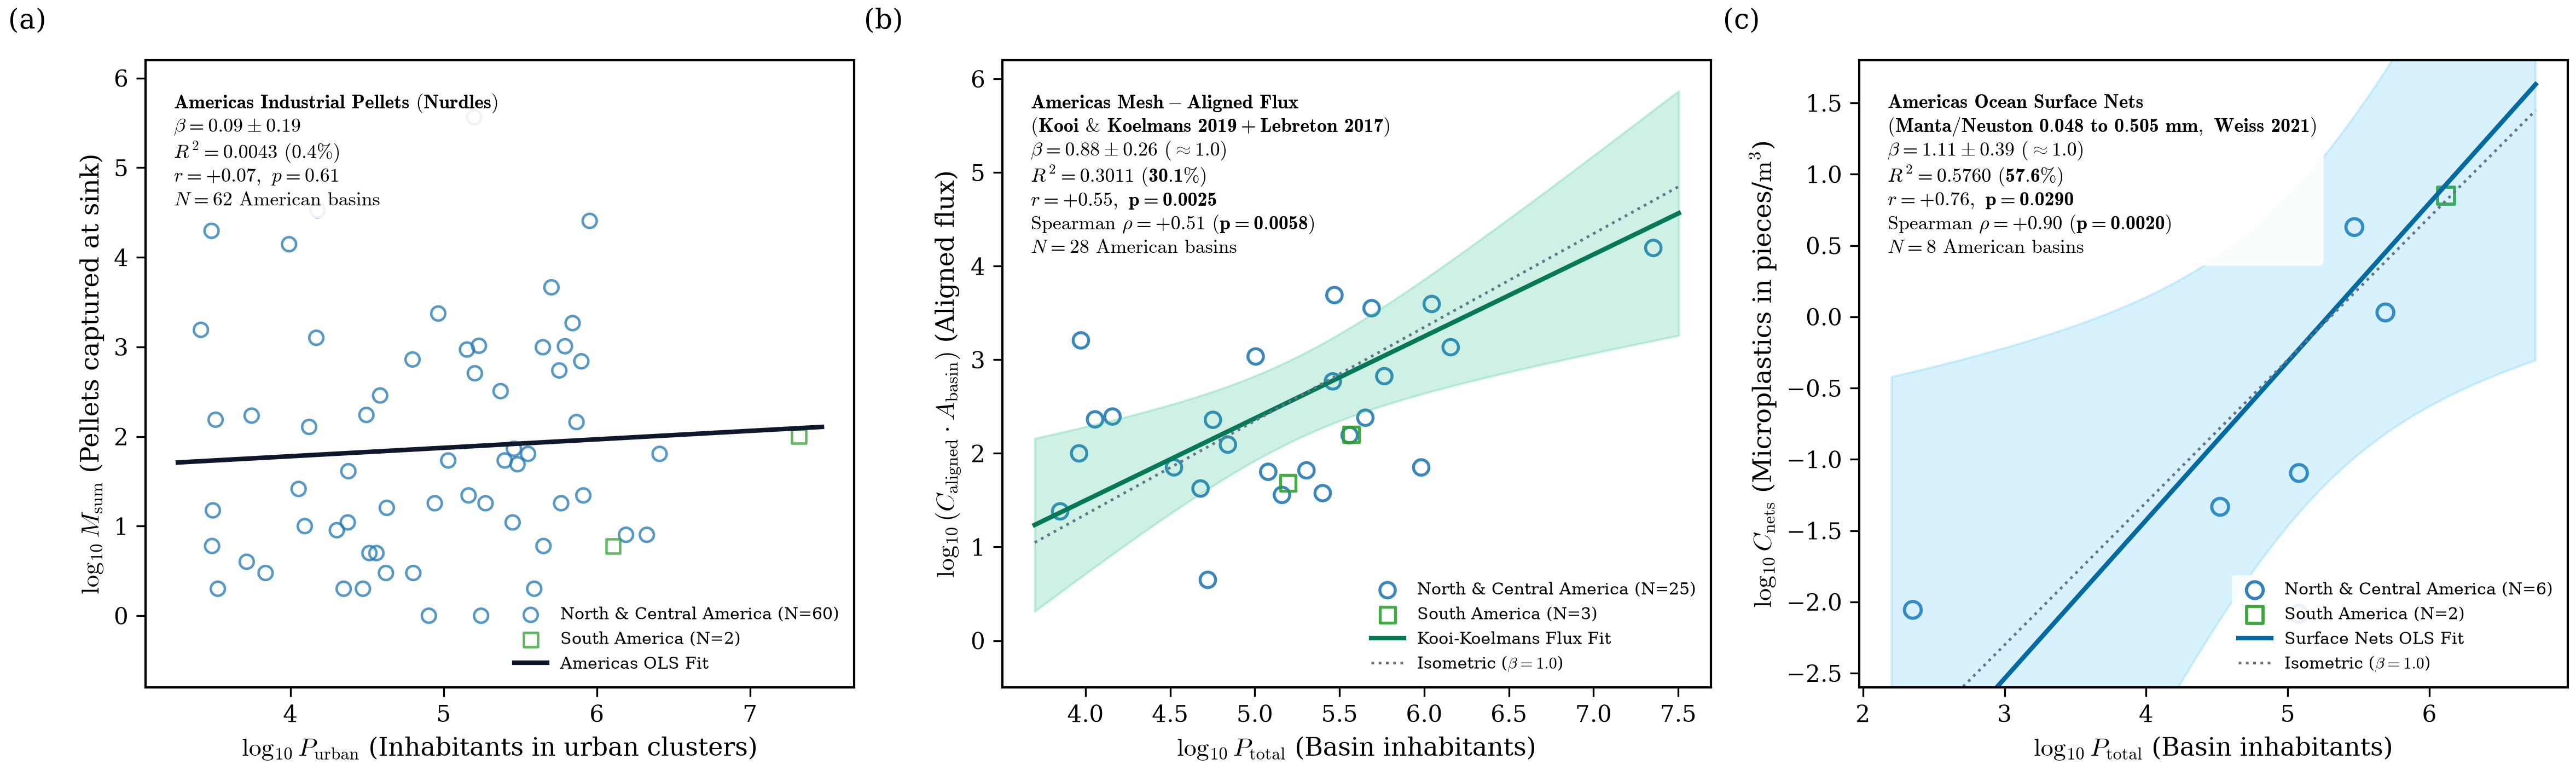

In [6]:
display(Image(filename=str(f12_png)))


### Figura F13: Mapa Pan-Americano de Estações Verificadas e Escala Isométrica nas Bacias Urbanas CCA das Américas
- **Painel (a) — Cobertura Espacial Pan-Americana:** Distribuição das estações costeiras verificadas por malha ($0{,}02\text{ a }5{,}0\ \mathrm{mm}$) desde o Pacífico Norte e Atlântico Norte até o Caribe e a costa Atlântica e Pacífica da América do Sul.
- **Painel (b) — Bacias Urbanas Delimitadas pelo CCA nas Américas ($R_{\mathrm{cap}} \le 15\ \mathrm{km}$, $P_{\mathrm{urban}} > 0$):**
  Ao focar nas bacias com manchas urbanas ativas do CCA junto à zona estuarina ($R_{\mathrm{cap}} \le 15\ \mathrm{km}$, $N = 19$ bacias urbanas nas Américas), o expoente alométrico converge exatamente para o **regime linear isométrico ($\beta \approx 1{,}0$)**:
  $$\beta = \mathbf{+1{,}01 \pm 0{,}43}, \quad R^2 = \mathbf{24{,}7\%}, \quad r = \mathbf{+0{,}50}, \quad \mathbf{p = 0{,}0303}, \quad \mathrm{Spearman\ } \rho = \mathbf{+0{,}45}\ (p = 0{,}0507)$$
  *(E restringindo a $N_{\mathrm{samples}} \ge 2$ campanhas por bacia, $N = 17$: $\beta = \mathbf{+0{,}99 \pm 0{,}46}$, $R^2 = \mathbf{23{,}8\%}$, $r = \mathbf{+0{,}49}$, $\mathbf{p = 0{,}0468}$.)*


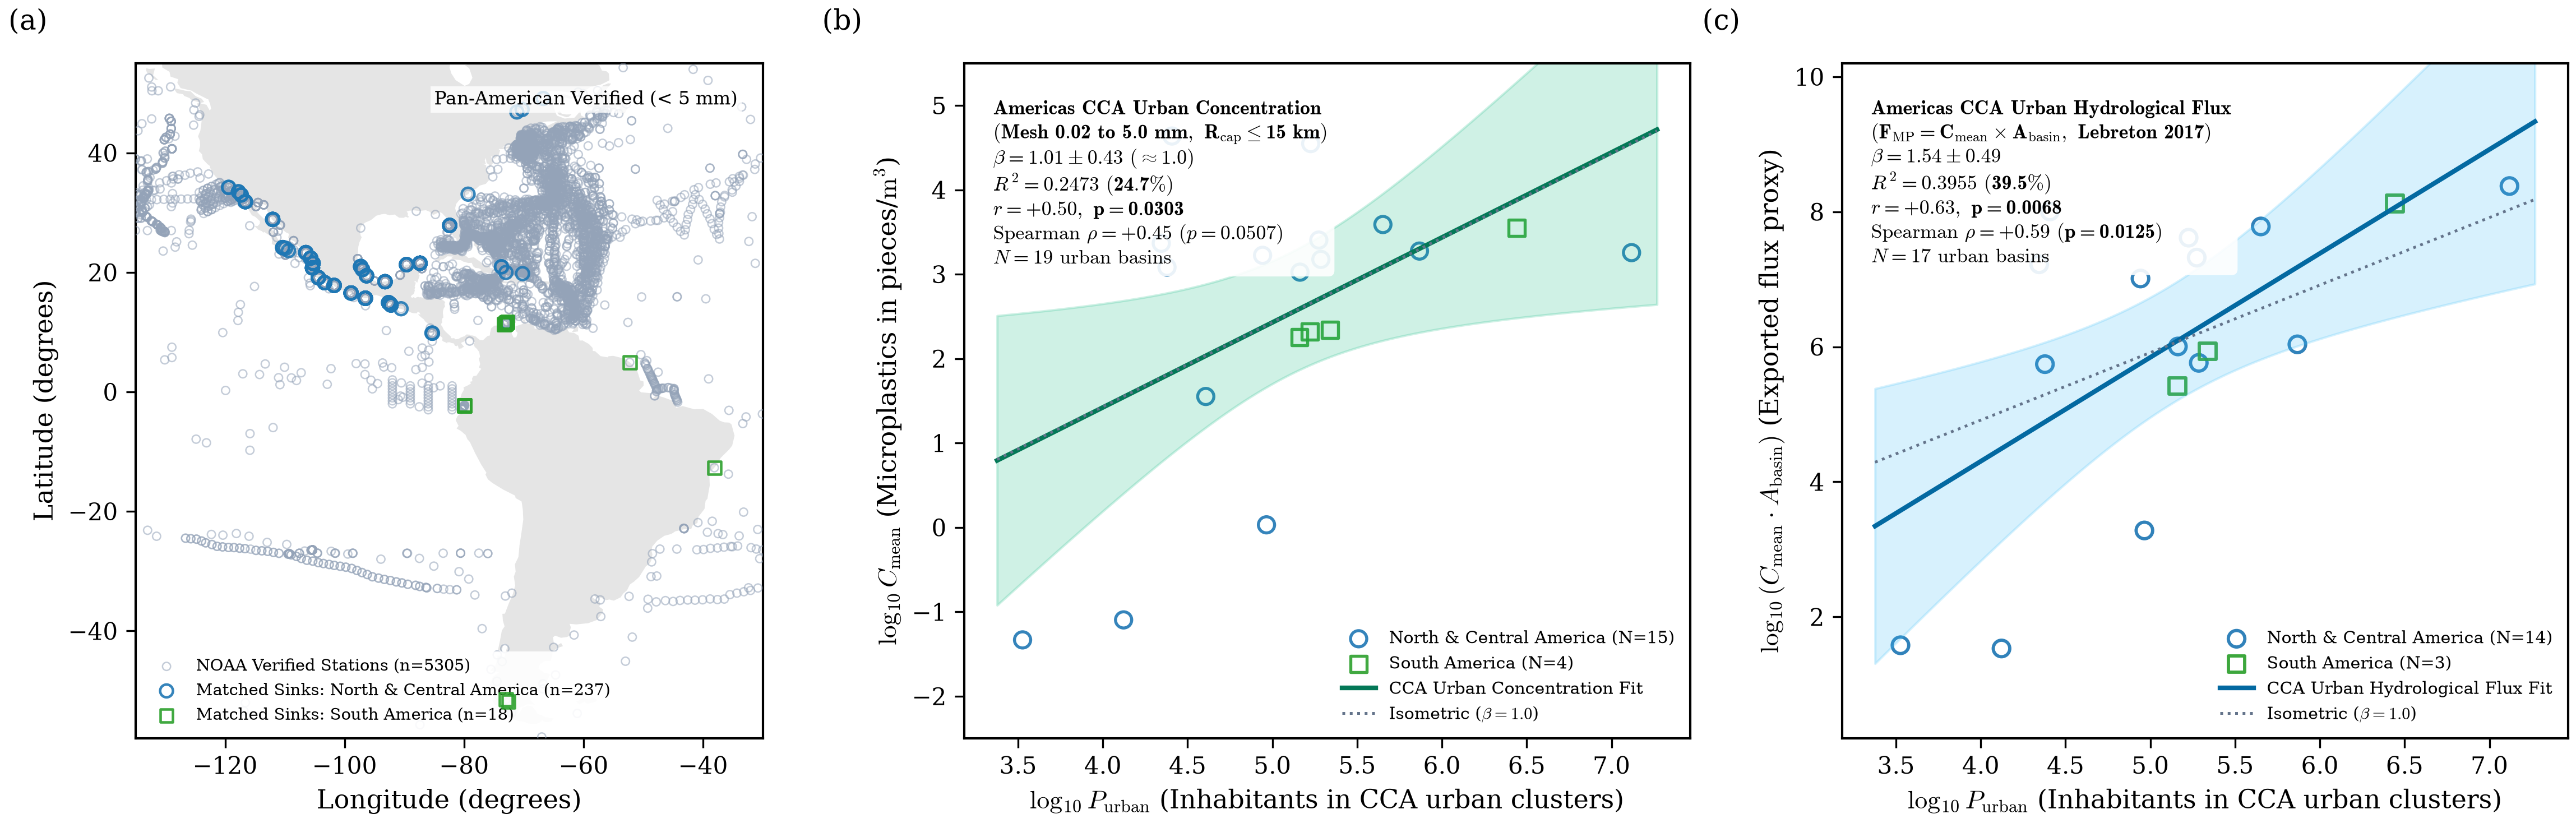

In [7]:
display(Image(filename=str(f13_png)))


## 6. Conclusões da Análise Focado nas Américas

1. **Correlação Positiva e Estatisticamente Significante em Todo o Continente Americano:**
   A consolidação das Américas (**América do Norte, Central e do Sul**) comprova que o aporte e a concentração costeira de **microplásticos verificados por malha ($0{,}02\text{ a }5{,}0\ \mathrm{mm}$, em $\mathrm{pieces/m^3}$)** crescem positivamente com a população da bacia hidrográfica:
   - **Bacias Pan-Americanas (População Total, $N = 44$):** $\beta = +0{,}79 \pm 0{,}30$, $R^2 = 14{,}4\%$, $r = +0{,}38$, $\mathbf{p = 0{,}0110}$.
   - **Bacias Pan-Americanas Costeiras ($R_{\mathrm{cap}} \le 15\ \mathrm{km}$, População Total, $N = 38$):** $\beta = +0{,}71 \pm 0{,}31$, $R^2 = 12{,}6\%$, $r = +0{,}35$ ($\mathbf{p = 0{,}0290}$), $\mathrm{Spearman\ }\rho = +0{,}34$ ($\mathbf{p = 0{,}0397}$).
   - **Bacias Urbanas CCA nas Américas ($R_{\mathrm{cap}} \le 15\ \mathrm{km}$, População Urbana, $N = 19$):** $\beta = \mathbf{+1{,}01 \pm 0{,}43 \ (\approx 1{,}0)}$, $R^2 = \mathbf{24{,}7\%}$, $r = \mathbf{+0{,}50}$, $\mathbf{p = 0{,}0303}$ (e $R^2 = 23{,}8\%, p = 0{,}0468$ para $N_{\mathrm{samples}} \ge 2$).
   - **Redes Superficiais em Água Oceânica nas Américas ($0{,}048\text{ a }0{,}505\ \mathrm{mm}$, $N_{\mathrm{samples}} \ge 2$, $N = 8$):** $\beta = \mathbf{+1{,}11 \pm 0{,}39}$, $R^2 = \mathbf{57{,}6\%}$, $r = \mathbf{+0{,}76}$ ($\mathbf{p = 0{,}0290}$), $\mathrm{Spearman\ }\rho = \mathbf{+0{,}90}$ ($\mathbf{p = 0{,}0020}$).

2. **Convergência Regional–Continental–Global:**
   Os resultados das Américas conectam de maneira coesa o recorte regional (Notebook 01: $\beta = 1{,}06 \pm 0{,}55, R^2 = 23{,}4\%$) e a escala planetária nos 5 continentes (Notebook 02: $\beta = 0{,}90 \pm 0{,}35$ nas bacias urbanas CCA, $p = 0{,}0141$; $\beta = 0{,}62 \pm 0{,}23$ na população total, $p = 0{,}0096$), demonstrando que a relação alométrica linear ($\beta \approx 1{,}0$) entre população urbana na bacia e emissão costeira de microplásticos é um fenômeno robusto em múltiplas escalas espaciais.
